EDA（Exploratory Data Analysis，探索性資料分析）。

- 資料有沒有問題？
- 量測值分布是否合理？
- 不同 Operator、Tool 之間有沒有明顯差異？
- 模擬資料是否真的呈現預期的偏差？

In [ ]:
# Objective:
# 1. Inspect data quality
# 2. Understand measurement distributions
# 3. Compare different operators and measurement tools
# 4. Evaluate measurement errors
#
# Dataset:
# - msa_data.csv
# - tool_matching_data.csv
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
# ============================================================
# 1. Define Project Paths
# ============================================================

ROOT = Path.cwd().parent
DATA_DIR = ROOT / "content"
FIG_DIR = ROOT / "content" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


In [ ]:
# ============================================================
# 2. Load Datasets
# ============================================================
msa = pd.read_csv(DATA_DIR / "msa_data.csv"
)
tool = pd.read_csv(DATA_DIR / "tool_matching_data.csv"
)
sns.set_theme(style="whitegrid")
NOMINAL_CD = 45.0  # nm


# ============================================================
# 3. Data Overview
# ============================================================
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print("\nMSA Dataset Shape:")
print(msa.shape)
print("\nTool Matching Dataset Shape:")
print(tool.shape)

# Display first five records
print("\nMSA Dataset Preview:")
print(msa.head())
print("\nTool Matching Dataset Preview:")
print(tool.head())

DATASET OVERVIEW

MSA Dataset Shape:
(60, 9)

Tool Matching Dataset Shape:
(180, 9)

MSA Dataset Preview:
  wafer_id lot_id tool_id operator_id  repeat        recipe  true_cd_nm  \
0     W001   L001  Tool_A        OP01       1  CD_RECIPE_01   45.243774   
1     W001   L001  Tool_A        OP01       2  CD_RECIPE_01   45.243774   
2     W001   L001  Tool_A        OP02       1  CD_RECIPE_01   45.243774   
3     W001   L001  Tool_A        OP02       2  CD_RECIPE_01   45.243774   
4     W001   L001  Tool_A        OP03       1  CD_RECIPE_01   45.243774   

   measured_cd_nm   timestamp  
0       45.349301  2026-11-05  
1       45.337109  2026-11-05  
2       45.331697  2026-11-05  
3       45.459043  2026-11-05  
4       45.239875  2026-11-05  

Tool Matching Dataset Preview:
  wafer_id lot_id tool_id operator_id  repeat        recipe  true_cd_nm  \
0     W001   L001  Tool_A        OP01       1  CD_RECIPE_01   43.979451   
1     W001   L001  Tool_A        OP01       2  CD_RECIPE_01   43.9794

In [ ]:
# ============================================================
# 4. Data Quality Inspection
# ============================================================
print("\n" + "=" * 60)
print("DATA QUALITY INSPECTION")
print("=" * 60)

# ------------------------------------------------------------
# 4.1 Data Types
# ------------------------------------------------------------
print("\n[MSA] Data Types:")
print(msa.dtypes)
print("\n[Tool Matching] Data Types:")
print(tool.dtypes)

# ------------------------------------------------------------
# 4.2 Missing Values
# ------------------------------------------------------------
print("\n[MSA] Missing Values:")
print(msa.isnull().sum())
print("\n[Tool Matching] Missing Values:")
print(tool.isnull().sum())

# Calculate missing value percentages
msa_missing_pct = (
    msa.isnull().mean() * 100
)
tool_missing_pct = (
    tool.isnull().mean() * 100
)

print("\n[MSA] Missing Value Percentage (%):")
print(msa_missing_pct.round(2))
print("\n[Tool Matching] Missing Value Percentage (%):")
print(tool_missing_pct.round(2))

# ------------------------------------------------------------
# 4.3 Duplicate Records
# ------------------------------------------------------------
print("\n[MSA] Duplicate Rows:")
print(msa.duplicated().sum())
print("\n[Tool Matching] Duplicate Rows:")
print(tool.duplicated().sum())

# ------------------------------------------------------------
# 4.4 Descriptive Statistics
# ------------------------------------------------------------

print("\n[MSA] Descriptive Statistics:")
print(
    msa[["true_cd_nm", "measured_cd_nm"]]
    .describe()
)
print("\n[Tool Matching] Descriptive Statistics:")
print(
    tool[["true_cd_nm", "measured_cd_nm"]]
    .describe()
)



DATA QUALITY INSPECTION

[MSA] Data Types:
wafer_id           object
lot_id             object
tool_id            object
operator_id        object
repeat              int64
recipe             object
true_cd_nm        float64
measured_cd_nm    float64
timestamp          object
dtype: object

[Tool Matching] Data Types:
wafer_id           object
lot_id             object
tool_id            object
operator_id        object
repeat              int64
recipe             object
true_cd_nm        float64
measured_cd_nm    float64
timestamp          object
dtype: object

[MSA] Missing Values:
wafer_id          0
lot_id            0
tool_id           0
operator_id       0
repeat            0
recipe            0
true_cd_nm        0
measured_cd_nm    0
timestamp         0
dtype: int64

[Tool Matching] Missing Values:
wafer_id          0
lot_id            0
tool_id           0
operator_id       0
repeat            0
recipe            0
true_cd_nm        0
measured_cd_nm    0
timestamp         0
dt

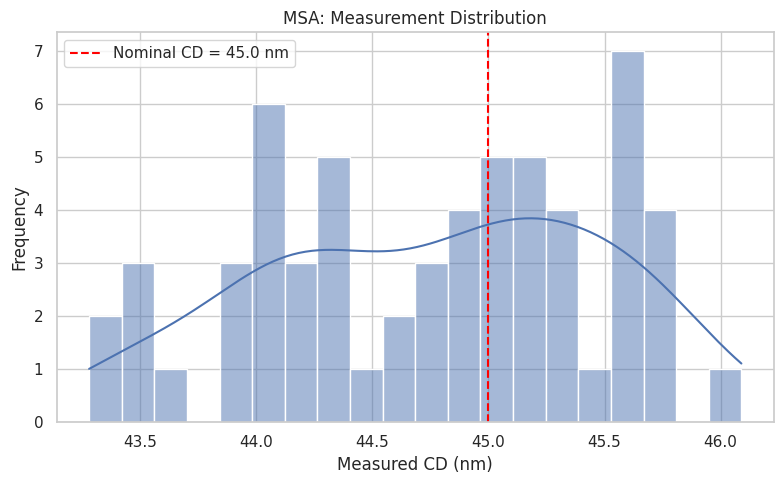

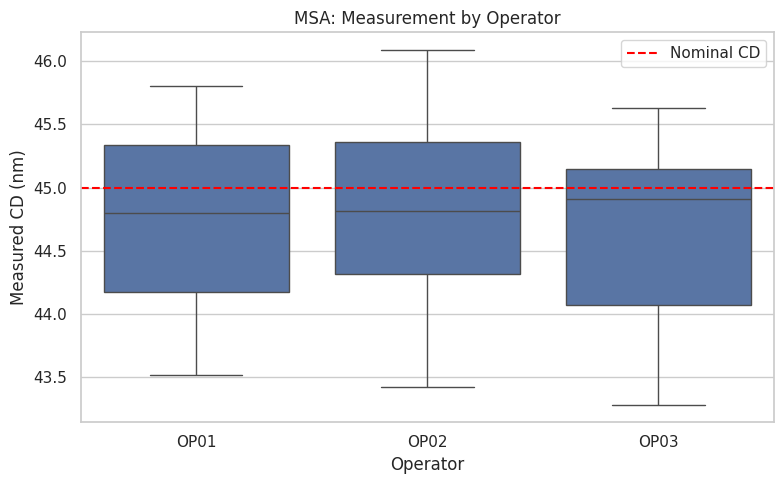

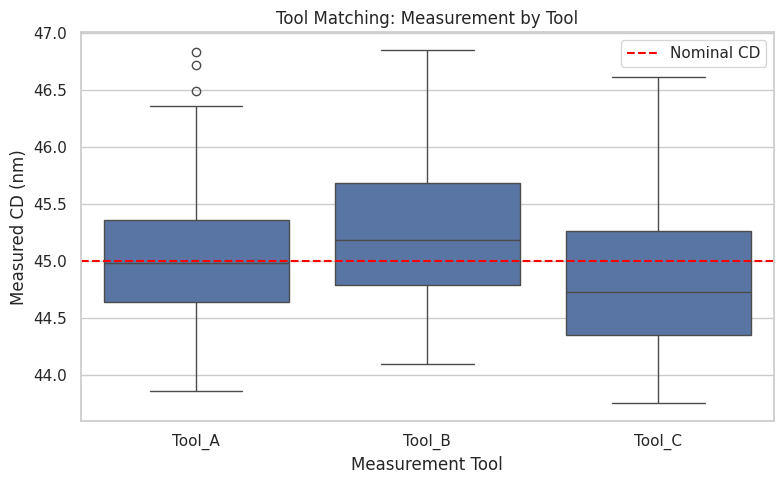

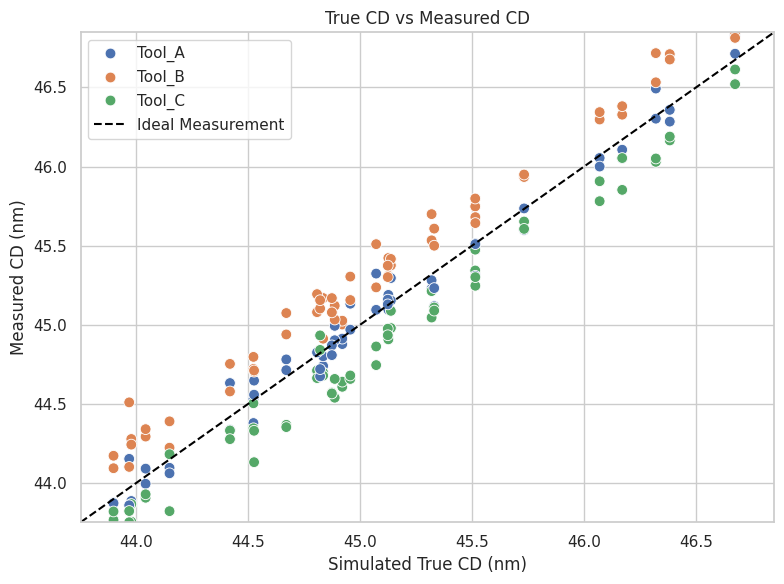

In [ ]:
# ============================================================
# 5. Visualization
# ============================================================


# ------------------------------------------------------------
# Figure 1: MSA Measurement Distribution
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

# Plot measurement distribution
sns.histplot(
    data=msa,
    x="measured_cd_nm",
    bins=20,
    kde=True
)

# Add nominal target line
plt.axvline(
    NOMINAL_CD,
    color="red",
    linestyle="--",
    label=f"Nominal CD = {NOMINAL_CD} nm"
)

plt.xlabel("Measured CD (nm)")
plt.ylabel("Frequency")
plt.title("MSA: Measurement Distribution")
plt.legend()

plt.tight_layout()

# Save figure
plt.savefig(
    FIG_DIR / "01_msa_distribution.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# Figure 2: Measurement Distribution by Operator
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

# Compare measurements from different operators
sns.boxplot(
    data=msa,
    x="operator_id",
    y="measured_cd_nm"
)

# Add nominal target line
plt.axhline(
    NOMINAL_CD,
    color="red",
    linestyle="--",
    label="Nominal CD"
)

plt.xlabel("Operator")
plt.ylabel("Measured CD (nm)")
plt.title("MSA: Measurement by Operator")
plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "02_operator_boxplot.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# Figure 3: Measurement Distribution by Tool
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

# Compare measurement results from different tools
sns.boxplot(
    data=tool,
    x="tool_id",
    y="measured_cd_nm"
)

# Add nominal target line
plt.axhline(
    NOMINAL_CD,
    color="red",
    linestyle="--",
    label="Nominal CD"
)

plt.xlabel("Measurement Tool")
plt.ylabel("Measured CD (nm)")
plt.title("Tool Matching: Measurement by Tool")
plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "03_tool_boxplot.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# Figure 4: True CD vs Measured CD
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

# Compare simulated true values and measured values
sns.scatterplot(
    data=tool,
    x="true_cd_nm",
    y="measured_cd_nm",
    hue="tool_id",
    s=60
)

# Determine plotting range
lower = min(
    tool["true_cd_nm"].min(),
    tool["measured_cd_nm"].min()
)

upper = max(
    tool["true_cd_nm"].max(),
    tool["measured_cd_nm"].max()
)

# Ideal measurement line: measured value = true value
plt.plot(
    [lower, upper],
    [lower, upper],
    color="black",
    linestyle="--",
    label="Ideal Measurement"
)

# Use identical axis ranges for fair comparison
plt.xlim(lower, upper)
plt.ylim(lower, upper)

plt.xlabel("Simulated True CD (nm)")
plt.ylabel("Measured CD (nm)")
plt.title("True CD vs Measured CD")
plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "04_true_vs_measured.png",
    dpi=300
)

plt.show()


TOOL MEASUREMENT ERROR SUMMARY
         mean_error  std_error     MAE  count
tool_id                                      
Tool_A      -0.0105     0.1002  0.0776     60
Tool_B       0.2429     0.0916  0.2429     60
Tool_C      -0.1861     0.1036  0.1916     60


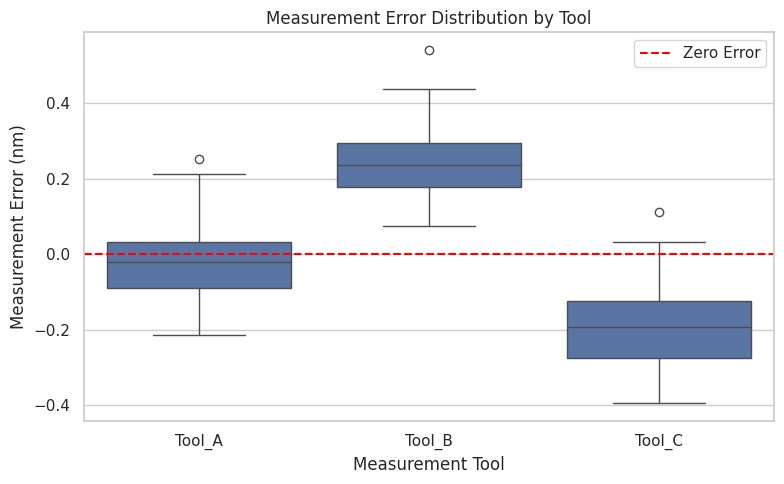

In [ ]:
# ============================================================
# 6. Measurement Error Analysis
# ============================================================

# Error = Measured Value - True Value
#
# Positive error: Measurement is higher than the true value
# Negative error: Measurement is lower than the true value

tool["error_nm"] = (
    tool["measured_cd_nm"]
    - tool["true_cd_nm"]
)

# Absolute error represents the magnitude of the error
tool["absolute_error_nm"] = (
    tool["error_nm"].abs()
)


# ------------------------------------------------------------
# 6.1 Measurement Error Summary by Tool
# ------------------------------------------------------------

tool_summary = (
    tool.groupby("tool_id")
    .agg(
        mean_error=("error_nm", "mean"),
        std_error=("error_nm", "std"),
        MAE=("absolute_error_nm", "mean"),
        count=("error_nm", "count")
    )
    .round(4)
)

print("\n" + "=" * 60)
print("TOOL MEASUREMENT ERROR SUMMARY")
print("=" * 60)

print(tool_summary)


# ------------------------------------------------------------
# 6.2 Measurement Error Distribution by Tool
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=tool,
    x="tool_id",
    y="error_nm"
)

# Zero represents perfect agreement with simulated true values
plt.axhline(
    0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Measurement Tool")
plt.ylabel("Measurement Error (nm)")
plt.title("Measurement Error Distribution by Tool")
plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "05_tool_error_boxplot.png",
    dpi=300
)

plt.show()

In [ ]:
# ============================================================
# 7. Operator Measurement Error Analysis
# ============================================================

# Calculate measurement error in MSA dataset
msa["error_nm"] = (
    msa["measured_cd_nm"]
    - msa["true_cd_nm"]
)

msa["absolute_error_nm"] = (
    msa["error_nm"].abs()
)

# Summarize measurement error by operator
operator_summary = (
    msa.groupby("operator_id")
    .agg(
        mean_error=("error_nm", "mean"),
        std_error=("error_nm", "std"),
        MAE=("absolute_error_nm", "mean"),
        count=("error_nm", "count")
    )
    .round(4)
)

print("\n" + "=" * 60)
print("OPERATOR MEASUREMENT ERROR SUMMARY")
print("=" * 60)

print(operator_summary)


# ============================================================
# 8. Export Analysis Results
# ============================================================

# Save summary tables
tool_summary.to_csv(
    ROOT / "content" / "tool_error_summary.csv"
)

operator_summary.to_csv(
    ROOT / "content" / "operator_error_summary.csv"
)

# Save datasets with calculated errors
tool.to_csv(
    ROOT / "content" / "tool_matching_with_error.csv",
    index=False
)

msa.to_csv(
    ROOT / "content" / "msa_with_error.csv",
    index=False
)



OPERATOR MEASUREMENT ERROR SUMMARY
             mean_error  std_error     MAE  count
operator_id                                      
OP01             0.0416     0.0882  0.0867     20
OP02             0.0704     0.0976  0.0847     20
OP03            -0.0478     0.0763  0.0689     20


In [ ]:
# ============================================================
# 9. Final Summary
# ============================================================

print("\n" + "=" * 60)
print("EDA COMPLETED")
print("=" * 60)

print(f"MSA records: {len(msa)}")
print(f"Tool Matching records: {len(tool)}")

print(f"MSA missing values: {msa.isnull().sum().sum()}")
print(f"Tool missing values: {tool.isnull().sum().sum()}")

print(f"MSA duplicate rows: {msa.duplicated().sum()}")
print(f"Tool duplicate rows: {tool.duplicated().sum()}")

print("\nFigures saved to:")
print(FIG_DIR)

print("\nAnalysis tables saved to:")
print(ROOT / "content")


EDA COMPLETED
MSA records: 60
Tool Matching records: 180
MSA missing values: 0
Tool missing values: 0
MSA duplicate rows: 0
Tool duplicate rows: 0

Figures saved to:
/content/figures

Analysis tables saved to:
/content


**結果**

1. Tool Matching：三台設備存在明顯的系統性偏差（Bias）。



2. Operator：三位操作人員的平均誤差相對接近，暫時看不出明顯的人員偏差。

**1 Tool Matching**

Tool A：

Mean Error = -0.0105 nm，接近 0，代表平均而言，量測值沒有明顯偏離模擬真值。

Tool B：

Mean Error = +0.2429 nm，代表量測結果平均比真值高約 0.243 nm。

Tool C：

Mean Error = -0.1861 nm，代表量測結果平均比真值低約 0.186 nm。

這表示三台設備即使量測相同 wafer，也可能得到不同的 CD 結果。

**2 Operator**

目前三位操作人員的 Mean Error 都在 ±0.1 nm 以內。

OP02 平均偏高，OP03 平均偏低，但差異不大。因此目前沒有明顯證據顯示某一位操作人員有嚴重的系統性偏差。

不代表三位操作人員的量測能力完全相同。後續要看：
- *Repeatability：同一操作人員、同一設備、同一樣本重複量測的變異。*
- *Reproducibility：不同操作人員之間的量測差異。*
- *Total Gage R&R：量測系統整體變異。*